In [2]:
# 엑셀 데이터 구조 확인
import pandas as pd
from pathlib import Path

raw_dir = Path("data/raw")

for year in range(2021, 2026):
    file_path = raw_dir / f"electricity_{year}.xlsx"

    print(f"\n========== {year}년 ==========")

    # 엑셀 시트 이름 확인
    excel = pd.ExcelFile(file_path)
    print("시트 목록:", excel.sheet_names)

    # 계약종별 데이터 확인
    df = pd.read_excel(
        file_path,
        sheet_name="계약종별",
        header=2
    )

    print("데이터 크기:", df.shape)
    print("컬럼 목록:", df.columns.tolist())
    print("첫 번째 데이터:")
    print(df.head(2).to_string(index=False))


========== 2021년 ==========
시트 목록: ['계약종별', '용도업종별']
데이터 크기: (1835, 16)
컬럼 목록: ['연도', '시도', '시군구', '계약종별', '1월', '2월', '3월', '4월', '5월', '6월', '7월', '8월', '9월', '10월', '11월', '12월']
첫 번째 데이터:
  연도    시도 시군구 계약종별        1월        2월       3월       4월       5월       6월        7월        8월        9월      10월      11월       12월
2021 서울특별시 종로구  주택용  25471662  23888545 20316994 20139886 19260662 21028845  26187114  33052390  24066790 20445031 20212978  21849769
2021 서울특별시 종로구  일반용 113082168 103460106 90283166 84892275 82623201 95379420 111593855 118671522 100688805 87018442 87190341 101720462

========== 2022년 ==========
시트 목록: ['계약종별', '용도업종별']
데이터 크기: (1835, 16)
컬럼 목록: ['연도', '시도', '시군구', '계약종별', '1월', '2월', '3월', '4월', '5월', '6월', '7월', '8월', '9월', '10월', '11월', '12월']
첫 번째 데이터:
  연도    시도 시군구 계약종별        1월        2월       3월       4월       5월       6월        7월        8월        9월      10월      11월       12월
2022 서울특별시 종로구  주택용  24799032  24030840 21082506 19922174 19122306 20446064  2

In [3]:
# 5년치 계약종별 데이터 합치기
import pandas as pd

data_list = []

for year in range(2021, 2026):

    file = f"data/raw/electricity_{year}.xlsx"

    df = pd.read_excel(
        file,
        sheet_name="계약종별",
        header=2
    )

    data_list.append(df)

df_all = pd.concat(data_list, ignore_index=True)

print(df_all.shape)
print(df_all.head())

(9170, 16)
     연도     시도  시군구 계약종별         1월         2월        3월        4월        5월  \
0  2021  서울특별시  종로구  주택용   25471662   23888545  20316994  20139886  19260662   
1  2021  서울특별시  종로구  일반용  113082168  103460106  90283166  84892275  82623201   
2  2021  서울특별시  종로구  교육용   10072542    9169051   7446466   6761511   6071807   
3  2021  서울특별시  종로구  산업용    6243796    6435682   5950803   6422580   5661896   
4  2021  서울특별시  종로구  농사용       5390       5073      3401      2288      2830   

         6월         7월         8월         9월       10월       11월        12월  
0  21028845   26187114   33052390   24066790  20445031  20212978   21849769  
1  95379420  111593855  118671522  100688805  87018442  87190341  101720462  
2   7468499    8634914    9043834    8551869   6928568   7391518    9188864  
3   5860405    6473303    6743565    6368171   5425599   5552168    6147328  
4       730        510       1113        691       741      1618       3905  


In [4]:
# 데이터 형태 변경
df_monthly = pd.melt(
    df_all,
    id_vars=["연도", "시도", "시군구", "계약종별"],
    var_name="월",
    value_name="사용량"
)

print(df_monthly.shape)
print(df_monthly.head())

(110040, 6)
     연도     시도  시군구 계약종별   월        사용량
0  2021  서울특별시  종로구  주택용  1월   25471662
1  2021  서울특별시  종로구  일반용  1월  113082168
2  2021  서울특별시  종로구  교육용  1월   10072542
3  2021  서울특별시  종로구  산업용  1월    6243796
4  2021  서울특별시  종로구  농사용  1월       5390


In [5]:
# 월 int 변경
df_monthly["월"] = (
    df_monthly["월"]
    .str.replace("월", "")
    .astype(int)
)

print(df_monthly.head())

     연도     시도  시군구 계약종별  월        사용량
0  2021  서울특별시  종로구  주택용  1   25471662
1  2021  서울특별시  종로구  일반용  1  113082168
2  2021  서울특별시  종로구  교육용  1   10072542
3  2021  서울특별시  종로구  산업용  1    6243796
4  2021  서울특별시  종로구  농사용  1       5390


In [6]:
# 날짜 컬럼 만들기 (연도-월)
df_monthly["날짜"] = pd.to_datetime(
    df_monthly["연도"].astype(str)
    + "-"
    + df_monthly["월"].astype(str)
).dt.to_period("M")

print(df_monthly.head())

     연도     시도  시군구 계약종별  월        사용량       날짜
0  2021  서울특별시  종로구  주택용  1   25471662  2021-01
1  2021  서울특별시  종로구  일반용  1  113082168  2021-01
2  2021  서울특별시  종로구  교육용  1   10072542  2021-01
3  2021  서울특별시  종로구  산업용  1    6243796  2021-01
4  2021  서울특별시  종로구  농사용  1       5390  2021-01


In [7]:
# 결측치 확인
print(df_monthly.isnull().sum())

연도      0
시도      0
시군구     0
계약종별    0
월       0
사용량     0
날짜      0
dtype: int64


In [8]:
# 같은 지역, 계약종별, 날짜가 중복되는지 확인
duplicate_count = df_monthly.duplicated(
    subset=["시도", "시군구", "계약종별", "날짜"]
).sum()

print("중복 데이터:", duplicate_count, "개")

중복 데이터: 0 개


In [9]:
# 음수와 0값 개수 확인
negative_count = (df_monthly["사용량"] < 0).sum()
zero_count = (df_monthly["사용량"] == 0).sum()

print("음수:", negative_count, "개")
print("0값:", zero_count, "개")

음수: 2 개
0값: 215 개


In [10]:
# 음수가 있는 행만 출력
negative_rows = df_monthly[df_monthly["사용량"] < 0]

print(negative_rows.to_string(index=False))

  연도      시도 시군구 계약종별  월        사용량      날짜
2022 세종특별자치시 세종시  일반용  1 -560490206 2022-01
2022 세종특별자치시 세종시  합 계  1 -298712777 2022-01


In [11]:
# 사용량이 0인 데이터
zero_rows = df_monthly[df_monthly["사용량"] == 0]

# 앞에서 10개만 확인
print(zero_rows.head(10).to_string(index=False))

  연도    시도 시군구 계약종별  월  사용량      날짜
2021  황해북도 개성시  주택용  1    0 2021-01
2021  황해북도 개성시  일반용  1    0 2021-01
2021  황해북도 개성시  산업용  1    0 2021-01
2021  황해북도 개성시  합 계  1    0 2021-01
2022  황해북도 개성시  주택용  1    0 2022-01
2022  황해북도 개성시  일반용  1    0 2022-01
2022  황해북도 개성시  산업용  1    0 2022-01
2022  황해북도 개성시  합 계  1    0 2022-01
2023 서울특별시  중구  농사용  1    0 2023-01
2023 대구광역시 군위군  주택용  1    0 2023-01


In [12]:
# 계약종별 0값 개수
print(zero_rows["계약종별"].value_counts())

계약종별
주택용    36
일반용    36
산업용    36
합 계    36
농사용    35
교육용    12
가로등    12
심 야    12
Name: count, dtype: int64


In [13]:
# 군위군 데이터만 선택
gunwi = df_monthly[df_monthly["시군구"] == "군위군"]

# 2023년 주택용 데이터만 확인
gunwi = gunwi[
    (gunwi["연도"] == 2023) &
    (gunwi["계약종별"] == "주택용")
]

print(gunwi[["시도", "날짜", "사용량"]].to_string(index=False))

   시도      날짜     사용량
대구광역시 2023-01       0
 경상북도 2023-01 2762104
대구광역시 2023-02       0
 경상북도 2023-02 2682772
대구광역시 2023-03       0
 경상북도 2023-03 2154455
대구광역시 2023-04       0
 경상북도 2023-04 2180751
대구광역시 2023-05       0
 경상북도 2023-05 2047290
대구광역시 2023-06       0
 경상북도 2023-06 2026580
대구광역시 2023-07 2154845
 경상북도 2023-07       0
대구광역시 2023-08 2723029
 경상북도 2023-08       0
대구광역시 2023-09 2494169
 경상북도 2023-09       0
대구광역시 2023-10 2113579
 경상북도 2023-10       0
대구광역시 2023-11 2155245
 경상북도 2023-11       0
대구광역시 2023-12 2382512
 경상북도 2023-12       0


In [14]:
# 군위군 행정구역 변경
# 2023년 군위군 주택용 사용량 통합
gunwi_total = gunwi.groupby("날짜")["사용량"].sum()

print(gunwi_total)

날짜
2023-01    2762104
2023-02    2682772
2023-03    2154455
2023-04    2180751
2023-05    2047290
2023-06    2026580
2023-07    2154845
2023-08    2723029
2023-09    2494169
2023-10    2113579
2023-11    2155245
2023-12    2382512
Freq: M, Name: 사용량, dtype: int64


In [15]:
# 음수 데이터 조사
# 세종시 일반용 데이터 선택
sejong = df_monthly[
    (df_monthly["시군구"] == "세종시") &
    (df_monthly["계약종별"] == "일반용")
]

# 2021~2023년 1월 사용량 확인
sejong_jan = sejong[sejong["월"] == 1]

print(sejong_jan[["날짜", "사용량"]].to_string(index=False))

     날짜        사용량
2021-01   74545029
2022-01 -560490206
2023-01   87157745
2024-01   90221471
2025-01   98553365


In [16]:
# 2022년 세종시 일반용 데이터만 선택
sejong_2022 = sejong[sejong["연도"] == 2022]

print(sejong_2022[["날짜", "사용량"]].to_string(index=False))

     날짜        사용량
2022-01 -560490206
2022-02   75866546
2022-03   67232381
2022-04   61396576
2022-05   60403809
2022-06   68074085
2022-07   80018568
2022-08   84679275
2022-09   74190204
2022-10   63635634
2022-11   62873727
2022-12   75647634


In [17]:
# 22년 1월 세종 일반용 전처리
# 21년과 23년 참고
# 데이터 전처리
df_clean = df_monthly.copy()

# 2021년, 2023년 세종시 일반용 1월 사용량
value_2021 = 74545029
value_2023 = 87157745

# 두 연도 평균으로 2022년 1월 추정
estimated = (value_2021 + value_2023) / 2

# 세종시 2022년 1월 일반용 보정
condition = (
    (df_clean["연도"] == 2022) &
    (df_clean["월"] == 1) &
    (df_clean["시군구"] == "세종시")
)

df_clean.loc[
    condition & (df_clean["계약종별"] == "일반용"),
    "사용량"
] = estimated

# 세종시 합계도 다시 계산
details = df_clean[
    condition & (df_clean["계약종별"] != "합 계")
]

new_total = details["사용량"].sum()

df_clean.loc[
    condition & (df_clean["계약종별"] == "합 계"),
    "사용량"
] = new_total

# 결과 확인
print("추정 일반용:", estimated)
print("재계산 합계:", new_total)
print("음수 개수:", (df_clean["사용량"] < 0).sum())

추정 일반용: 80851387.0
재계산 합계: 342628816
음수 개수: 0


In [18]:
# 전국 월별 전력 사용량 집계
total_df = df_clean[df_clean["계약종별"] == "합 계"]

monthly_total = total_df.groupby("날짜")["사용량"].sum()

print(monthly_total.head(12))

날짜
2021-01    48755561392
2021-02    45187962749
2021-03    43074364361
2021-04    41899676610
2021-05    40842275451
2021-06    42031874106
2021-07    45971797058
2021-08    48929955530
2021-09    44818885195
2021-10    41838221376
2021-11    42829616368
2021-12    47250619115
Freq: M, Name: 사용량, dtype: int64


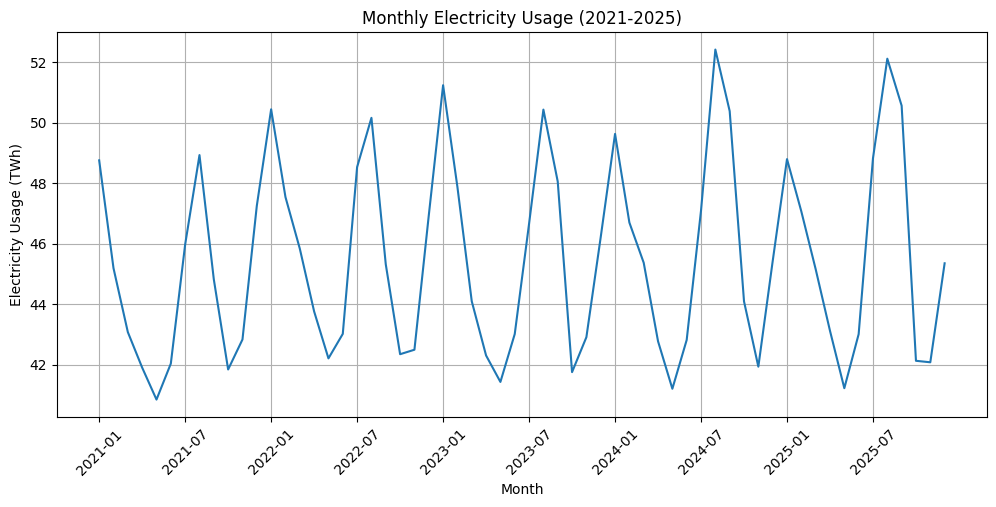

In [19]:
# 그래프 그리기
import matplotlib.pyplot as plt

# kWh를 TWh로 변환
monthly_twh = monthly_total / 1_000_000_000

# 그래프 크기 설정
plt.figure(figsize=(12, 5))

# 선 그래프 그리기
plt.plot(monthly_twh.index.astype(str), monthly_twh.values)

# 제목과 축 이름
plt.title("Monthly Electricity Usage (2021-2025)")
plt.xlabel("Month")
plt.ylabel("Electricity Usage (TWh)")

# X축 날짜 간격 조절
plt.xticks(range(0, 60, 6), rotation=45)

# 격자 표시
plt.grid(True)

# 그래프 출력
plt.show()

In [20]:
# 7~8월 1월달에 사용량이 늘어남 계절성으로 보임

In [21]:
# 연도별 전력 사용량 분석
# 연도별 전국 전력 사용량 계산
yearly_total = df_clean[
    df_clean["계약종별"] == "합 계"
].groupby("연도")["사용량"].sum()

# TWh 단위로 변환
yearly_twh = yearly_total / 1_000_000_000

print(yearly_twh)

연도
2021    533.430809
2022    548.574083
2023    545.965955
2024    549.820665
2025    549.417259
Name: 사용량, dtype: float64


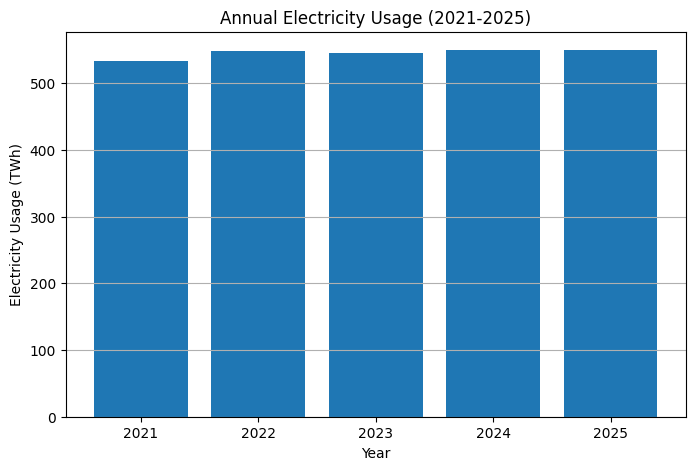

In [22]:
plt.figure(figsize=(8, 5))

plt.bar(yearly_twh.index.astype(str), yearly_twh.values)

plt.title("Annual Electricity Usage (2021-2025)")
plt.xlabel("Year")
plt.ylabel("Electricity Usage (TWh)")

plt.grid(axis="y")
plt.show()

In [23]:
# 계약종별 사용량 분석 (합계 제외)
contract_df = df_clean[df_clean["계약종별"] != "합 계"]

# 계약종별 사용량 합산
contract_total = contract_df.groupby("계약종별")["사용량"].sum()

# TWh 단위 변환
contract_twh = contract_total / 1_000_000_000

# 사용량이 큰 순서대로 정렬
contract_twh = contract_twh.sort_values(ascending=False)

print(contract_twh)

계약종별
산업용    1444.357868
일반용     651.350731
주택용     418.722379
농사용     105.397392
교육용      45.972556
심 야      44.322568
가로등      17.085278
Name: 사용량, dtype: float64


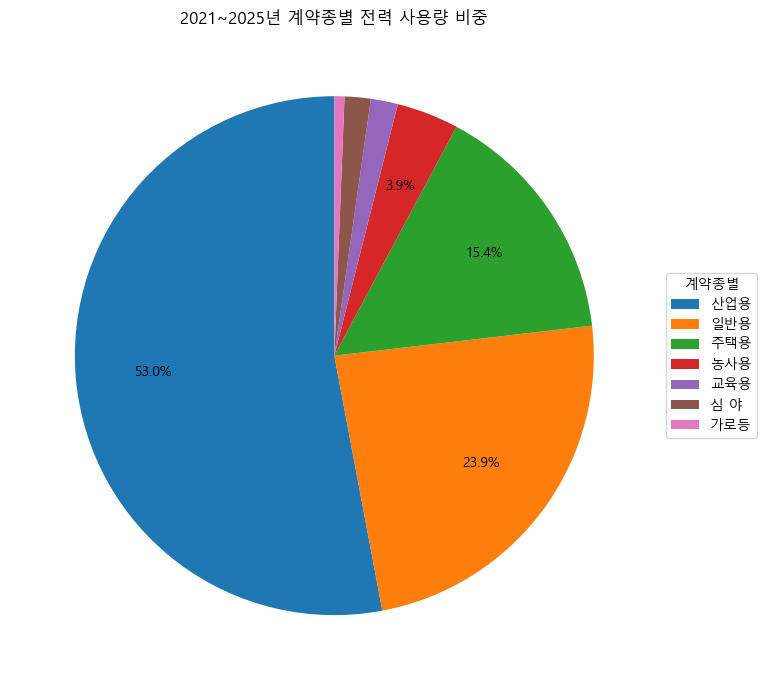

In [24]:
# 계약종별 비중 시각화

# 한글 폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 계약종별 전력 사용량 비중
plt.figure(figsize=(10, 7))

plt.pie(
    contract_twh.values,
    autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",
    startangle=90,
    pctdistance=0.7
)

# 범례를 오른쪽에 표시
plt.legend(
    contract_twh.index,
    title="계약종별",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("2021~2025년 계약종별 전력 사용량 비중")
plt.tight_layout()
plt.show()

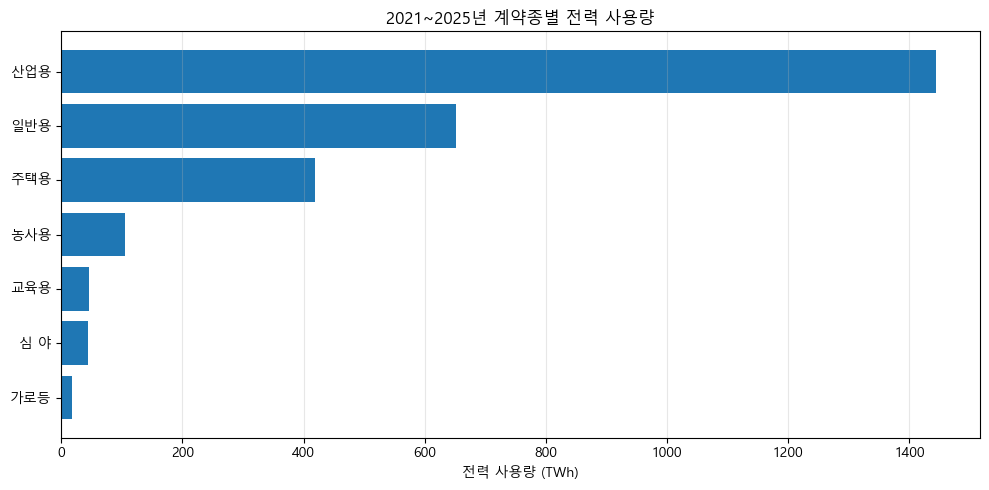

In [25]:
# 계약종별 사용량 가로 막대그래프
plt.figure(figsize=(10, 5))

plt.barh(contract_twh.index, contract_twh.values)

plt.gca().invert_yaxis()

plt.title("2021~2025년 계약종별 전력 사용량")
plt.xlabel("전력 사용량 (TWh)")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
#  계약종별 월 전력 사용량 패턴 분석

# 계약종별, 월별 전국 사용량 합산
contract_monthly = contract_df.groupby(
    ["연도", "월", "계약종별"]
)["사용량"].sum().reset_index()

# 5년간 월별 평균 계산
contract_avg = contract_monthly.groupby(
    ["월", "계약종별"]
)["사용량"].mean().reset_index()

# TWh로 변환
contract_avg["사용량"] = contract_avg["사용량"] / 1_000_000_000

print(contract_avg.head(10))

   월 계약종별        사용량
0  1  가로등   0.327431
1  1  교육용   1.032460
2  1  농사용   2.107974
3  1  산업용  25.183077
4  1  심 야   1.520253
5  1  일반용  12.392675
6  1  주택용   7.209426
7  2  가로등   0.308922
8  2  교육용   0.859027
9  2  농사용   2.096761


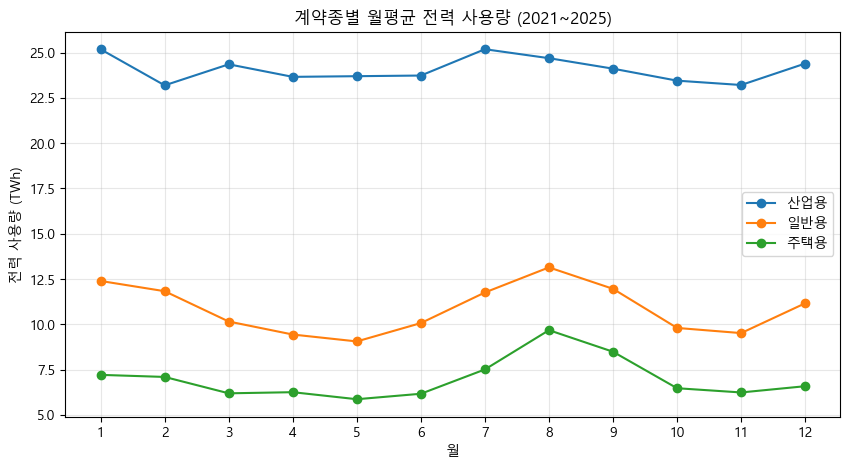

In [27]:
plt.figure(figsize=(10, 5))

for contract in ["산업용", "일반용", "주택용"]:
    data = contract_avg[contract_avg["계약종별"] == contract]

    plt.plot(
        data["월"],
        data["사용량"],
        marker="o",
        label=contract
    )

plt.title("계약종별 월평균 전력 사용량 (2021~2025)")
plt.xlabel("월")
plt.ylabel("전력 사용량 (TWh)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

계약종별 전력 사용 패턴 분석

2021~2025년 계약종별 월평균 전력 사용량을 분석한 결과, 산업용은 전체 사용량이 가장 크지만 월별 변동은 상대적으로 작게 나타났다. 반면 일반용과 주택용은 여름철 사용량 증가가 뚜렷하게 관찰되었다. 따라서 전력 수요 예측 모델에서는 월별 계절성과 계약종별 특성을 함께 고려할 필요가 있다.

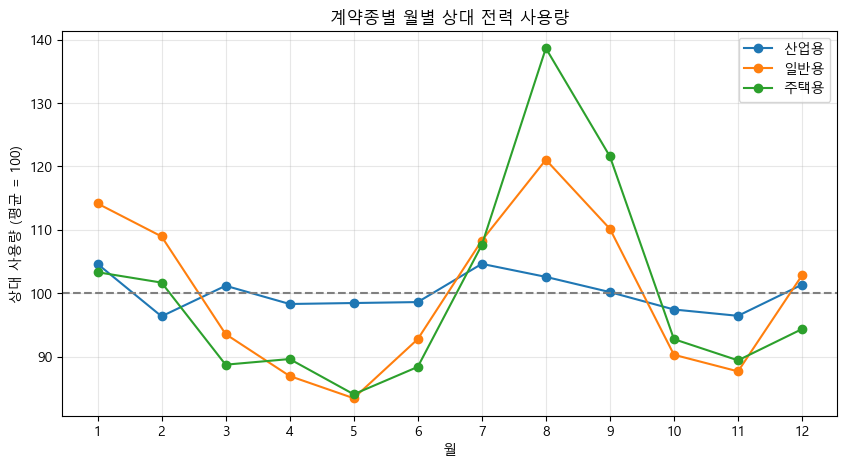

In [28]:
# 계약종별 평균을 기준으로 상대적인 사용량 계산
contract_avg["상대사용량"] = (
    contract_avg["사용량"] /
    contract_avg.groupby("계약종별")["사용량"].transform("mean")
) * 100

# 그래프 생성
plt.figure(figsize=(10, 5))

for contract in ["산업용", "일반용", "주택용"]:
    data = contract_avg[contract_avg["계약종별"] == contract]

    plt.plot(
        data["월"],
        data["상대사용량"],
        marker="o",
        label=contract
    )

plt.axhline(100, color="gray", linestyle="--")

plt.title("계약종별 월별 상대 전력 사용량")
plt.xlabel("월")
plt.ylabel("상대 사용량 (평균 = 100)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [29]:
# 전처리 데이터 저장
df_clean.to_csv(
    "data/processed/electricity_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

print("전처리 데이터 저장 완료!")

전처리 데이터 저장 완료!
